# Bangalore House Price Prediction — Supervised Regression

Predict house prices (in Lakhs) from location, area, bathrooms, balconies and BHK using a Random Forest Regressor.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

plt.rcParams['figure.dpi'] = 110

## 1. Load the dataset

In [2]:
df = pd.read_csv('../datasets/bangalore_house_data.csv')
print(df.shape)
df.head()

(13320, 9)


,area_type,availability,location,size,society,total_sqft,bath,balcony,price
0,Super built-up Area,19-Dec,Electronic City Phase II,2 BHK,Coomee,1056,2.0,1.0,39.07
1,Plot Area,Ready To Move,Chikka Tirupathi,4 Bedroom,Theanmp,2600,5.0,3.0,120.00
2,Built-up Area,Ready To Move,Uttarahalli,3 BHK,NaN,1440,2.0,3.0,62.00
3,Super built-up Area,Ready To Move,Lingadheeranahalli,3 BHK,Soiewre,1521,3.0,1.0,95.00
4,Super built-up Area,Ready To Move,Kothanur,2 BHK,NaN,1200,2.0,1.0,51.00


## 2. Clean the data

In [3]:
print(df.isnull().sum())

df = df[['location', 'size', 'total_sqft', 'bath', 'balcony', 'price']].dropna()

def convert_sqft(x):
    try:
        return float(x)
    except (ValueError, TypeError):
        return np.nan   # ranges like '2100 - 2850'

df['total_sqft'] = df['total_sqft'].apply(convert_sqft)
df = df.dropna()
df['BHK'] = df['size'].apply(lambda x: int(x.split(' ')[0]))
print('\nClean shape:', df.shape)
df.describe()

area_type          0
availability       0
location           1
size              16
society         5502
total_sqft         0
bath              73
balcony          609
price              0
dtype: int64

Clean shape: (12524, 7)


,total_sqft,bath,balcony,price,BHK
count,12524.000000,12524.000000,12524.000000,12524.000000,12524.000000
mean,1510.454911,2.616257,1.603881,106.121675,2.740339
std,1162.445581,1.219231,0.803443,132.213979,1.202674
min,5.000000,1.000000,0.000000,8.000000,1.000000
25%,1100.000000,2.000000,1.000000,49.500000,2.000000
50%,1260.000000,2.000000,2.000000,70.000000,3.000000
75%,1640.000000,3.000000,2.000000,115.000000,3.000000
max,52272.000000,40.000000,3.000000,2912.000000,43.000000


## 3. Explore the data

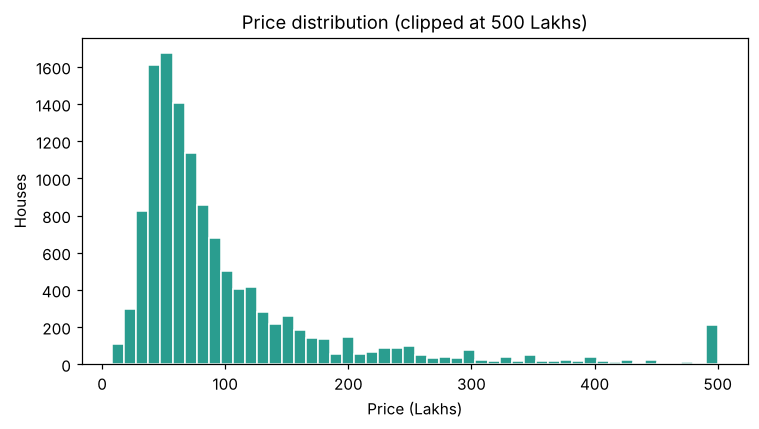

In [4]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(df['price'].clip(upper=500), bins=50, color='#2a9d8f', edgecolor='white')
ax.set_title('Price distribution (clipped at 500 Lakhs)')
ax.set_xlabel('Price (Lakhs)')
ax.set_ylabel('Houses')
plt.tight_layout()
plt.savefig('../images/price_distribution.png')
plt.show()

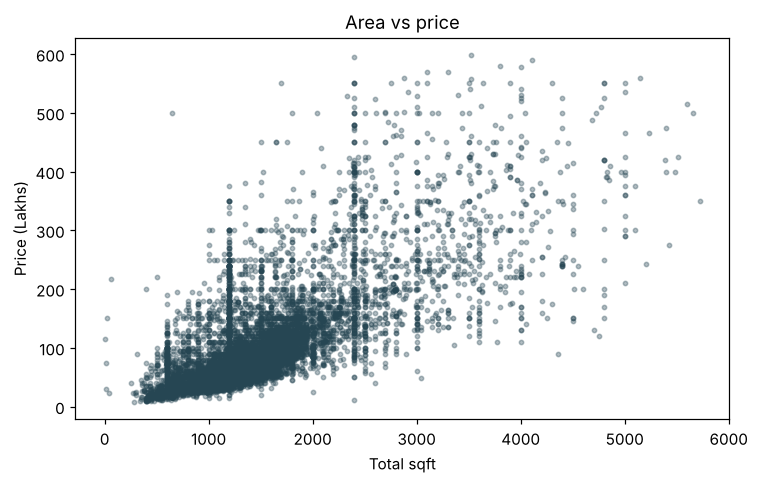

In [5]:
fig, ax = plt.subplots(figsize=(7, 4.5))
sub = df[(df['total_sqft'] < 6000) & (df['price'] < 600)]
ax.scatter(sub['total_sqft'], sub['price'], s=8, alpha=0.35, color='#264653')
ax.set_title('Area vs price')
ax.set_xlabel('Total sqft')
ax.set_ylabel('Price (Lakhs)')
plt.tight_layout()
plt.savefig('../images/sqft_vs_price.png')
plt.show()

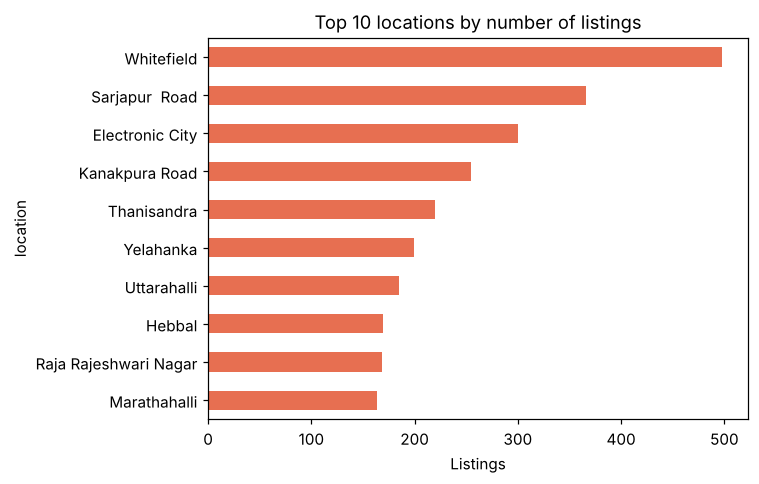

In [6]:
top = df['location'].value_counts().head(10)
fig, ax = plt.subplots(figsize=(7, 4.5))
top.sort_values().plot(kind='barh', color='#e76f51', ax=ax)
ax.set_title('Top 10 locations by number of listings')
ax.set_xlabel('Listings')
plt.tight_layout()
plt.savefig('../images/top_locations.png')
plt.show()

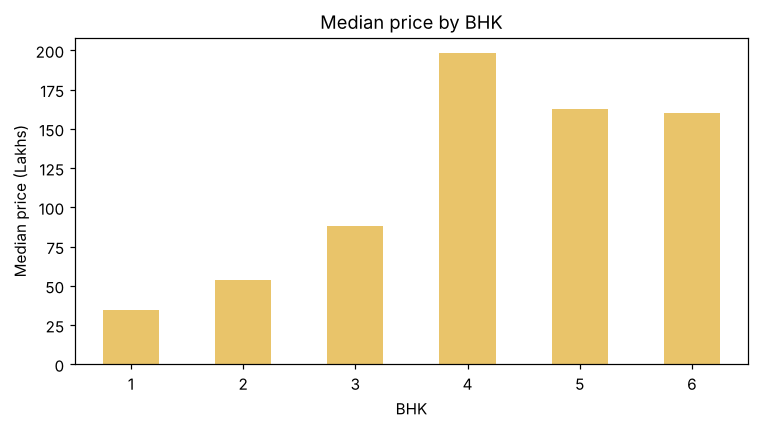

In [7]:
fig, ax = plt.subplots(figsize=(7, 4))
df[df['BHK'] <= 6].groupby('BHK')['price'].median().plot(kind='bar', color='#e9c46a', ax=ax)
ax.set_title('Median price by BHK')
ax.set_ylabel('Median price (Lakhs)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig('../images/price_by_bhk.png')
plt.show()

## 4. Build the model pipeline

In [8]:
X = df[['location', 'total_sqft', 'bath', 'balcony', 'BHK']]
y = df['price']

preprocessor = ColumnTransformer([
    ('cat', OneHotEncoder(handle_unknown='ignore'), ['location']),
    ('num', SimpleImputer(strategy='median'), ['total_sqft', 'bath', 'balcony', 'BHK']),
])

model = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', RandomForestRegressor(n_estimators=100, random_state=42)),
])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](5,)","['location','total_sqft','bath','balcony','BHK']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,5
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with 

## 5. Evaluate

In [9]:
pred = model.predict(X_test)
print('Mean Absolute Error:', round(mean_absolute_error(y_test, pred), 2), 'Lakhs')
print('R2 Score:', round(r2_score(y_test, pred), 3))

Mean Absolute Error: 32.07 Lakhs
R2 Score: 0.533


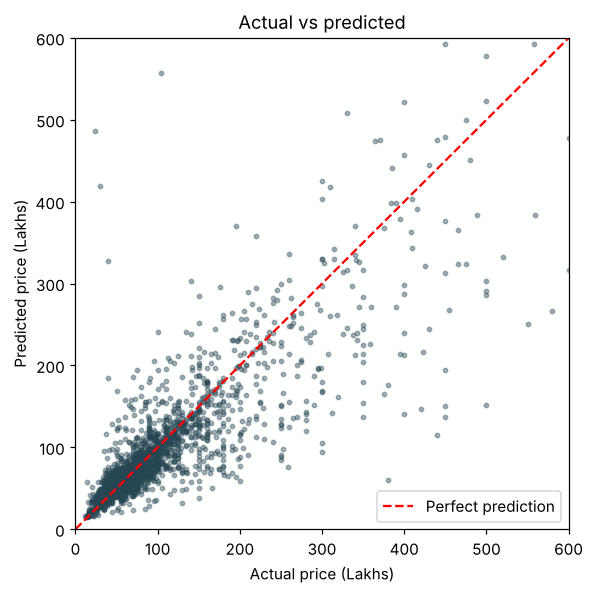

In [10]:
fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.scatter(y_test, pred, s=8, alpha=0.4, color='#264653')
lim = 600
ax.plot([0, lim], [0, lim], 'r--', label='Perfect prediction')
ax.set_xlim(0, lim); ax.set_ylim(0, lim)
ax.set_xlabel('Actual price (Lakhs)')
ax.set_ylabel('Predicted price (Lakhs)')
ax.set_title('Actual vs predicted')
ax.legend()
plt.tight_layout()
plt.savefig('../images/actual_vs_predicted.png')
plt.show()

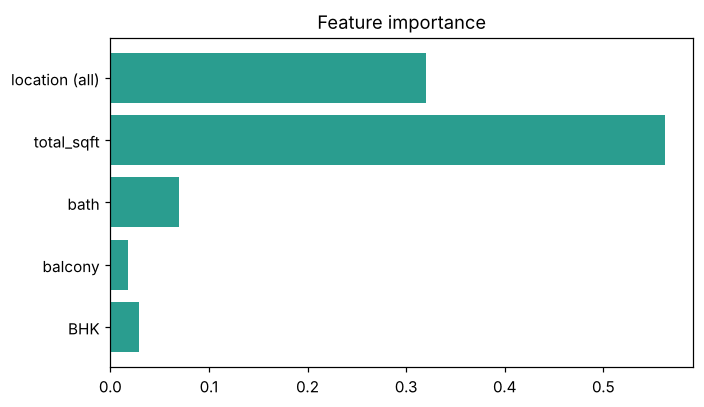

In [11]:
# Importance of numeric features vs all location columns combined
imp = model.named_steps['regressor'].feature_importances_
n_num = 4
names = ['location (all)', 'total_sqft', 'bath', 'balcony', 'BHK']
vals = [imp[:-n_num].sum(), *imp[-n_num:]]
fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.barh(names[::-1], vals[::-1], color='#2a9d8f')
ax.set_title('Feature importance')
plt.tight_layout()
plt.savefig('../images/feature_importance.png')
plt.show()

## 6. Predict a new house

In [12]:
sample = pd.DataFrame({'location': ['Whitefield'], 'total_sqft': [1200], 'bath': [2], 'balcony': [1], 'BHK': [2]})
print('Predicted price:', round(model.predict(sample)[0], 2), 'Lakhs')

Predicted price: 45.58 Lakhs
